In [ ]:
# ============================================================
# NEUROSCAN AI - Phase 1: 2D Brain Tumor Classifier
# Cell 1: GPU check & Google Drive connection
# ============================================================
import torch
from google.colab import drive

print("PyTorch version :", torch.__version__)
print("GPU available   :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name        :", torch.cuda.get_device_name(0))

drive.mount("/content/drive")

import os
folder = "/content/drive/MyDrive/neuroscan-ai"
print("\nFiles in your neuroscan-ai folder:")
for f in os.listdir(folder):
    size_mb = os.path.getsize(os.path.join(folder, f)) / 1e6
    print(f"  {f}  ({size_mb:.1f} MB)")

PyTorch version : 2.11.0+cu130
GPU available   : True
GPU name        : Tesla T4
Mounted at /content/drive

Files in your neuroscan-ai folder:
  archive (2).zip  (164.7 MB)


In [ ]:
# ============================================================
# Cell 2: Unzip dataset & inspect structure
# ============================================================
import os, zipfile
from collections import Counter

ZIP_PATH = "/content/drive/MyDrive/neuroscan-ai/archive (2).zip"
DATA_ROOT = "/content/brain_mri"

# 1) Extract to local disk (skip if already done)
if not os.path.exists(DATA_ROOT):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_ROOT)
    print("Extracted to", DATA_ROOT)
else:
    print("Already extracted at", DATA_ROOT)

# 2) Show top-level folder structure (2 levels deep)
print("\nFolder structure:")
for root, dirs, files in os.walk(DATA_ROOT):
    depth = root[len(DATA_ROOT):].count(os.sep)
    if depth <= 2:
        print(f"{'  ' * depth}{os.path.basename(root) or DATA_ROOT}/  ({len(files)} files)")

# 3) Count images per split and class
IMG_EXT = (".jpg", ".jpeg", ".png")
counts = {}
for root, dirs, files in os.walk(DATA_ROOT):
    imgs = [f for f in files if f.lower().endswith(IMG_EXT)]
    if imgs:
        parts = os.path.relpath(root, DATA_ROOT).split(os.sep)
        counts[tuple(parts[-2:])] = len(imgs)

print("\nImages per split / class:")
for (split, cls), n in sorted(counts.items()):
    print(f"  {split:10} {cls:12} {n}")
print("\nTotal images:", sum(counts.values()))

Extracted to /content/brain_mri

Folder structure:
brain_mri/  (0 files)
  Testing/  (0 files)
    pituitary/  (400 files)
    notumor/  (400 files)
    glioma/  (400 files)
    meningioma/  (400 files)
  Training/  (0 files)
    pituitary/  (1400 files)
    notumor/  (1400 files)
    glioma/  (1400 files)
    meningioma/  (1400 files)

Images per split / class:
  Testing    glioma       400
  Testing    meningioma   400
  Testing    notumor      400
  Testing    pituitary    400
  Training   glioma       1400
  Training   meningioma   1400
  Training   notumor      1400
  Training   pituitary    1400

Total images: 7200


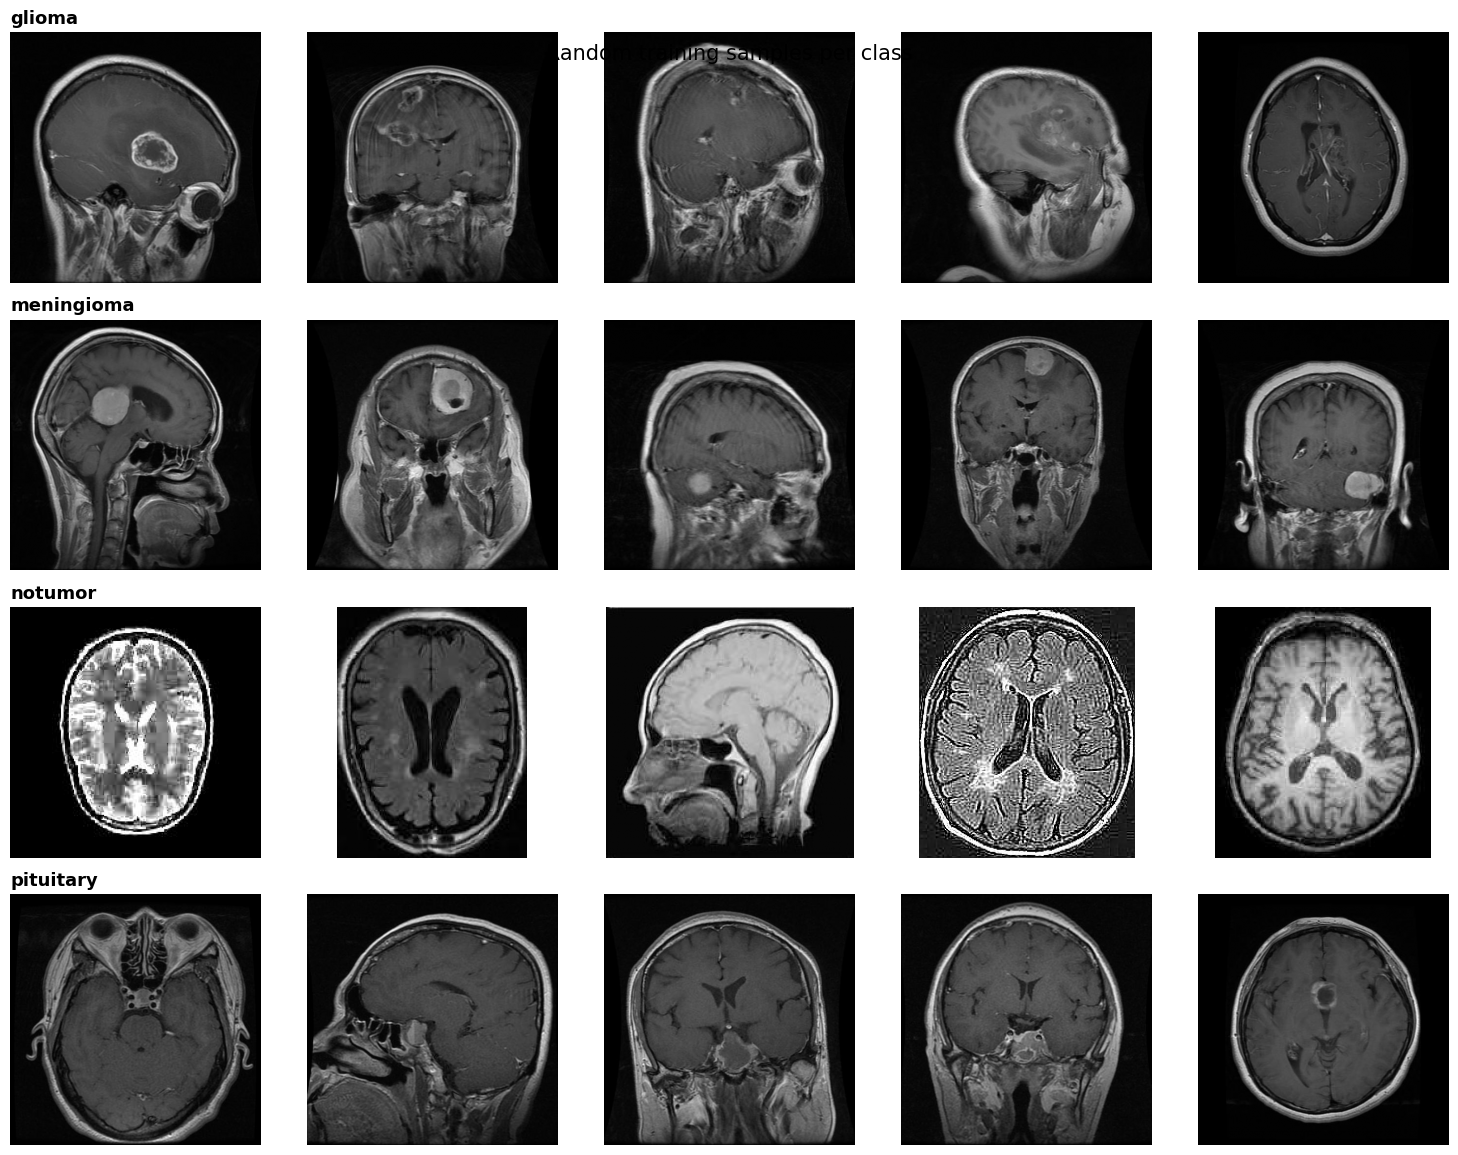

Image modes (sample of 400): {'L': 167, 'RGB': 233}
Most common sizes (width, height): [((512, 512), 286), ((225, 225), 21), ((630, 630), 4), ((200, 252), 4), ((192, 192), 4)]
Unique sizes in sample: 63

Total images checked          : 7200
Unique image files (by hash)  : 7013
Duplicate groups              : 153
  - within one split          : 153
  - shared Training & Testing : 0   <-- leakage if > 0
  - same image, different label: 0


In [ ]:
# ============================================================
# Cell 3: Sample images, image properties, duplicate/leakage check
# ============================================================
import random, hashlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
random.seed(42)

def list_images(split, cls):
    d = os.path.join(DATA_ROOT, split, cls)
    return [os.path.join(d, f) for f in sorted(os.listdir(d)) if f.lower().endswith(IMG_EXT)]

# ---------- 1) Sample grid: 5 random images per class ----------
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for r, cls in enumerate(CLASSES):
    for c, path in enumerate(random.sample(list_images("Training", cls), 5)):
        axes[r, c].imshow(Image.open(path).convert("L"), cmap="gray")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(cls, loc="left", fontsize=13, fontweight="bold")
plt.suptitle("Random training samples per class", fontsize=15, y=0.93)
plt.tight_layout()
plt.show()

# ---------- 2) Image properties (sample of 400 images) ----------
all_paths = [p for s in ("Training", "Testing") for cls in CLASSES for p in list_images(s, cls)]
sample = random.sample(all_paths, 400)
sizes, modes = [], Counter()
for p in sample:
    with Image.open(p) as im:
        sizes.append(im.size)
        modes[im.mode] += 1
print("Image modes (sample of 400):", dict(modes))
print("Most common sizes (width, height):", Counter(sizes).most_common(5))
print(f"Unique sizes in sample: {len(set(sizes))}")

# ---------- 3) Exact-duplicate check using file hashes ----------
def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

hashes = {}   # hash -> list of (split, class, path)
for s in ("Training", "Testing"):
    for cls in CLASSES:
        for p in list_images(s, cls):
            hashes.setdefault(md5(p), []).append((s, cls, p))

dup_groups = {h: v for h, v in hashes.items() if len(v) > 1}
within = sum(1 for v in dup_groups.values() if len({x[0] for x in v}) == 1)
across = sum(1 for v in dup_groups.values() if len({x[0] for x in v}) == 2)
label_conflicts = sum(1 for v in dup_groups.values() if len({x[1] for x in v}) > 1)

print(f"\nTotal images checked          : {sum(len(v) for v in hashes.values())}")
print(f"Unique image files (by hash)  : {len(hashes)}")
print(f"Duplicate groups              : {len(dup_groups)}")
print(f"  - within one split          : {within}")
print(f"  - shared Training & Testing : {across}   <-- leakage if > 0")
print(f"  - same image, different label: {label_conflicts}")

Images per class after de-duplication:
            train  val  test
class                       
glioma       1190  210   386
meningioma   1178  208   398
notumor      1089  192   400
pituitary    1157  205   400
TOTAL        4614  815  1584

Saved splits.csv to Google Drive

Batch tensor shape: (32, 3, 224, 224) | labels: [0, 3, 1, 3, 0, 0, 1, 0]
Batches -> train: 145, val: 26, test: 50


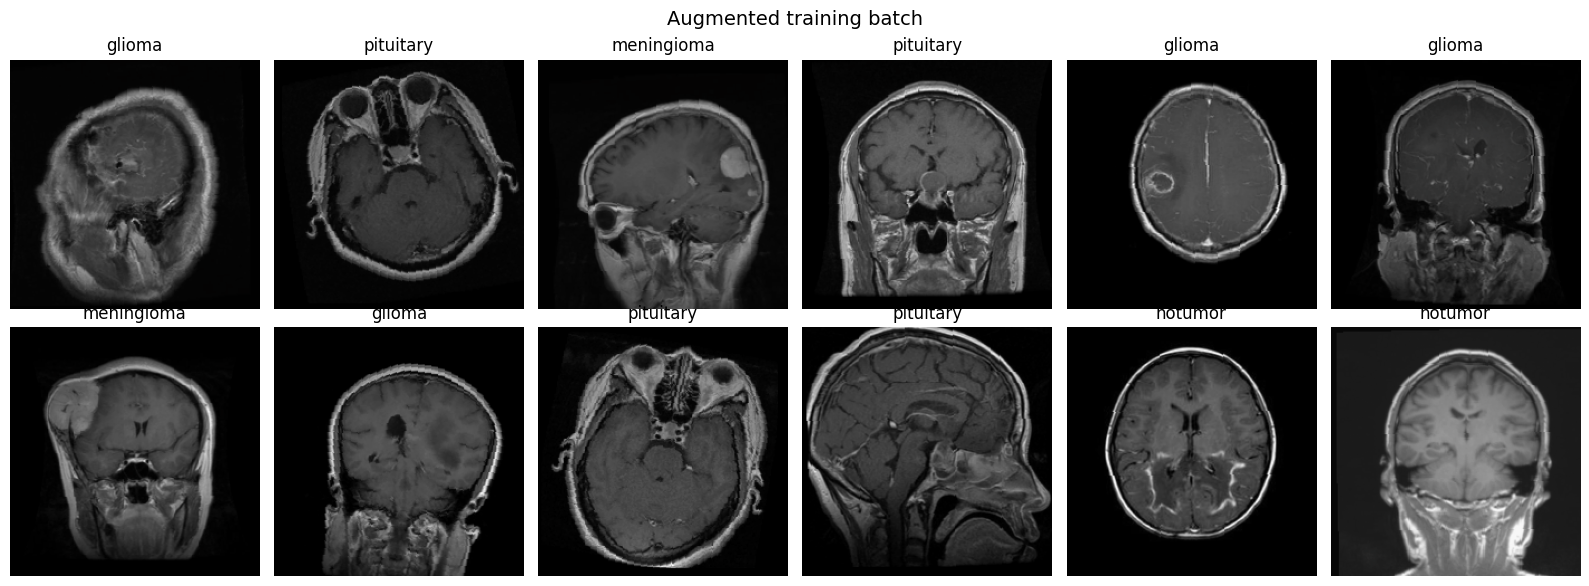

In [ ]:
# ============================================================
# Cell 4: Clean splits, transforms, DataLoaders
# ============================================================
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)

CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}

# ---------- 1) De-duplicated table (keep first copy of each unique image) ----------
rows = []
for h, items in hashes.items():
    split, cls, path = sorted(items, key=lambda x: x[2])[0]
    rows.append({"path": path, "label": CLASS_TO_IDX[cls], "class": cls, "orig_split": split})
df = pd.DataFrame(rows)

trainval_df = df[df["orig_split"] == "Training"].reset_index(drop=True)
test_df     = df[df["orig_split"] == "Testing"].reset_index(drop=True)

# ---------- 2) Stratified train / validation split ----------
train_df, val_df = train_test_split(
    trainval_df, test_size=0.15, stratify=trainval_df["label"], random_state=SEED
)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)

summary = pd.DataFrame({
    "train": train_df["class"].value_counts(),
    "val":   val_df["class"].value_counts(),
    "test":  test_df["class"].value_counts(),
}).loc[CLASSES]
summary.loc["TOTAL"] = summary.sum()
print("Images per class after de-duplication:")
print(summary)

# Save the split so it can be reloaded if Colab restarts
split_all = pd.concat([train_df.assign(split="train"), val_df.assign(split="val"),
                       test_df.assign(split="test")])
split_all.to_csv("/content/drive/MyDrive/neuroscan-ai/splits.csv", index=False)
print("\nSaved splits.csv to Google Drive")

# ---------- 3) Transforms ----------
IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(10),
    transforms.RandomAffine(0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# ---------- 4) Dataset & loaders ----------
class MRIDataset(Dataset):
    def __init__(self, frame, tf):
        self.paths, self.labels, self.tf = frame["path"].tolist(), frame["label"].tolist(), tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")   # handles grayscale + RGB files
        return self.tf(img), self.labels[i]

BATCH = 32
train_loader = DataLoader(MRIDataset(train_df, train_tf), batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(MRIDataset(val_df,   eval_tf),  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(MRIDataset(test_df,  eval_tf),  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

xb, yb = next(iter(train_loader))
print(f"\nBatch tensor shape: {tuple(xb.shape)} | labels: {yb[:8].tolist()}")
print(f"Batches -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

# ---------- 5) Preview of augmented training images ----------
mean_t, std_t = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, img, lab in zip(axes.ravel(), xb[:12], yb[:12]):
    ax.imshow((img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy())
    ax.set_title(IDX_TO_CLASS[int(lab)]); ax.axis("off")
plt.suptitle("Augmented training batch", fontsize=14)
plt.tight_layout(); plt.show()

/tmp/ipykernel_556/104068552.py:44: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Epoch  1/12 | train loss 0.7911 acc 0.7666 | val loss 0.5354 acc 0.9080 | 32s  <- best, saved
Epoch  2/12 | train loss 0.5303 acc 0.9239 | val loss 0.5294 acc 0.9227 | 34s  <- best, saved
Epoch  3/12 | train loss 0.4750 acc 0.9506 | val loss 0.4389 acc 0.9607 | 34s  <- best, saved
Epoch  4/12 | train loss 0.4318 acc 0.9720 | val loss 0.4997 acc 0.9350 | 32s
Epoch  5/12 | train loss 0.4123 acc 0.9829 | val loss 0.3895 acc 0.9865 | 32s  <- best, saved
Epoch  6/12 | train loss 0.4000 acc 0.9853 | val loss 0.3948 acc 0.9840 | 32s
Epoch  7/12 | train loss 0.3838 acc 0.9931 | val loss 0.3746 acc 0.9926 | 31s  <- best, saved
Epoch  8/12 | train loss 0.3759 acc 0.9957 | val loss 0.3905 acc 0.9791 | 33s
Epoch  9/12 | train loss 0.3736 acc 0.9965 | val loss 0.3717 acc 0.9926 | 32s
Epoch 10/12 | train loss 0.3731 acc 0.9972 | val loss 0.3697 acc 0.9926 | 32s
Epoch 11/12 | train loss 0.3689 acc 0.9974 | val loss 0.3690 acc 0.9926 | 31s
Epoch 12/12 | train loss 0.3669 acc 0.9978 | val loss 0.3676 a

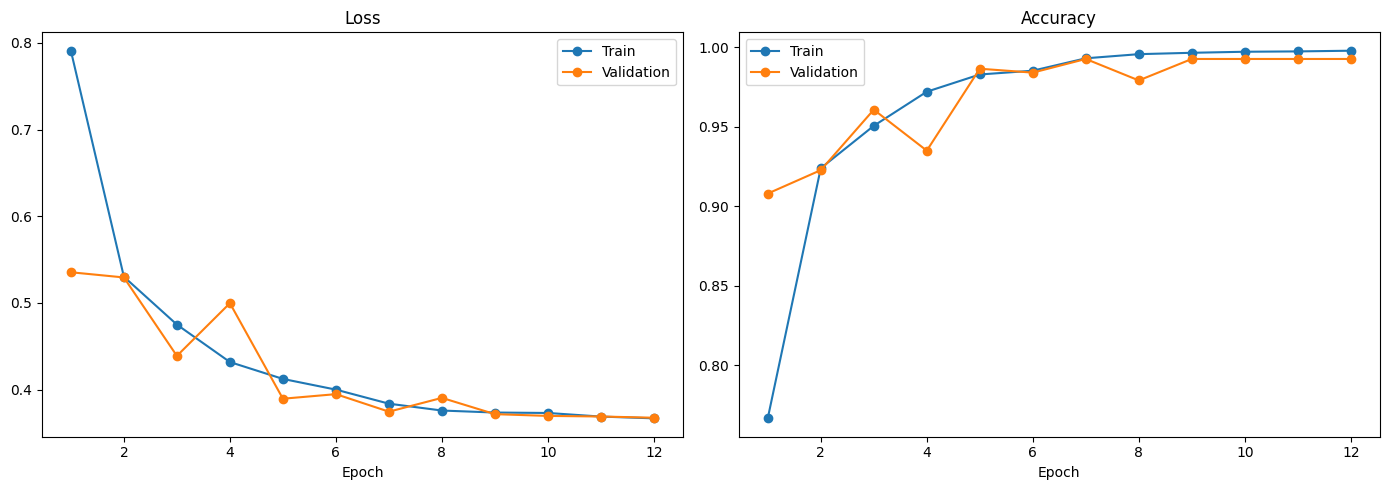

In [ ]:
# ============================================================
# Cell 5 (corrected): ResNet18 - full schedule, best checkpoint saved
# ============================================================
import time, copy

# ---------- 1) Fresh model, optimizer, schedule ----------
torch.manual_seed(SEED)
model = build_model().to(device)

EPOCHS = 12
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=3e-4, epochs=EPOCHS, steps_per_epoch=len(train_loader), pct_start=0.2
)
scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")

# ---------- 2) Train for the full schedule ----------
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_acc, best_state = 0.0, None

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
        history[k].append(v)

    flag = ""
    if va_acc > best_acc:
        best_acc, best_state = va_acc, copy.deepcopy(model.state_dict())
        torch.save({
            "state_dict": best_state, "classes": CLASSES, "img_size": IMG_SIZE,
            "mean": MEAN, "std": STD, "val_acc": best_acc, "epoch": epoch,
        }, CKPT)
        flag = "  <- best, saved"

    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | {time.time()-t0:.0f}s{flag}")

model.load_state_dict(best_state)
print(f"\nBest validation accuracy: {best_acc:.4f}")

# ---------- 3) Learning curves ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ep = range(1, len(history["train_loss"]) + 1)
axes[0].plot(ep, history["train_loss"], marker="o", label="Train")
axes[0].plot(ep, history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(ep, history["train_acc"], marker="o", label="Train")
axes[1].plot(ep, history["val_acc"], marker="o", label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/neuroscan-ai/learning_curves.png", dpi=150)
plt.show()

In [ ]:
import seaborn as sns

Test images            : 1584
Test accuracy          : 0.9564
Balanced accuracy      : 0.9554
Misclassified          : 69

              precision    recall  f1-score   support

      glioma     0.9969    0.8368    0.9099       386
  meningioma     0.8977    0.9925    0.9427       398
     notumor     0.9501    1.0000    0.9744       400
   pituitary     0.9950    0.9925    0.9937       400

    accuracy                         0.9564      1584
   macro avg     0.9599    0.9554    0.9552      1584
weighted avg     0.9597    0.9564    0.9556      1584



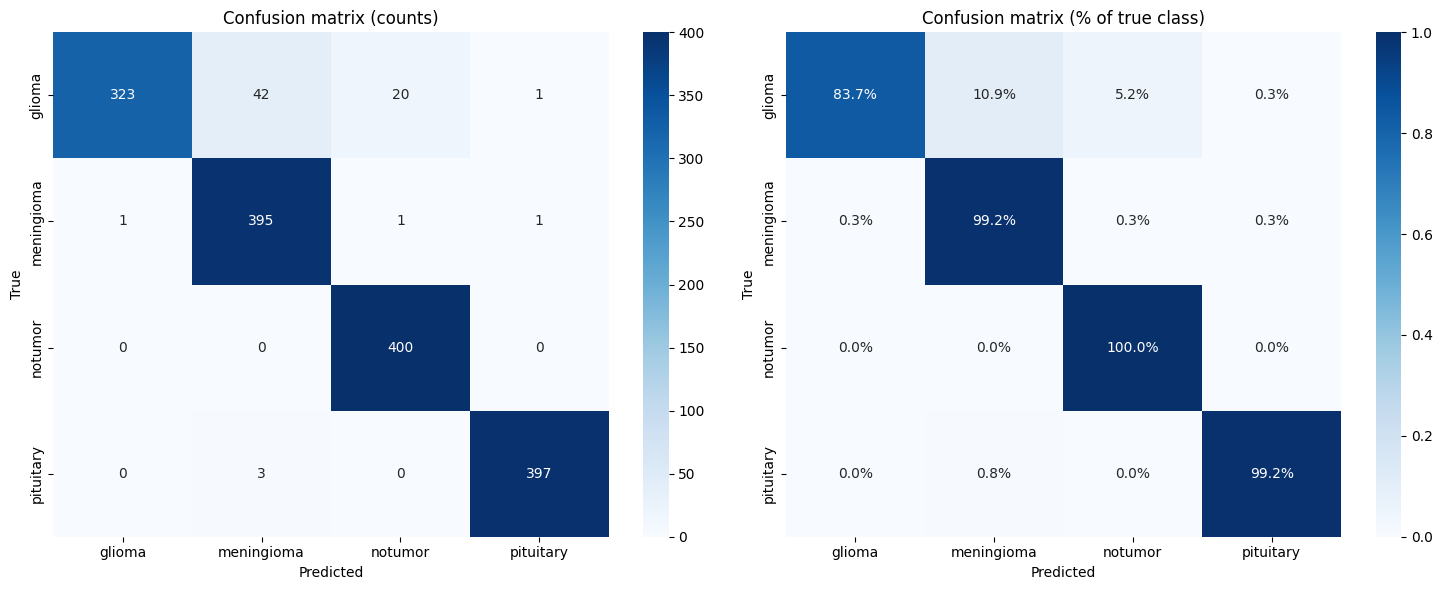

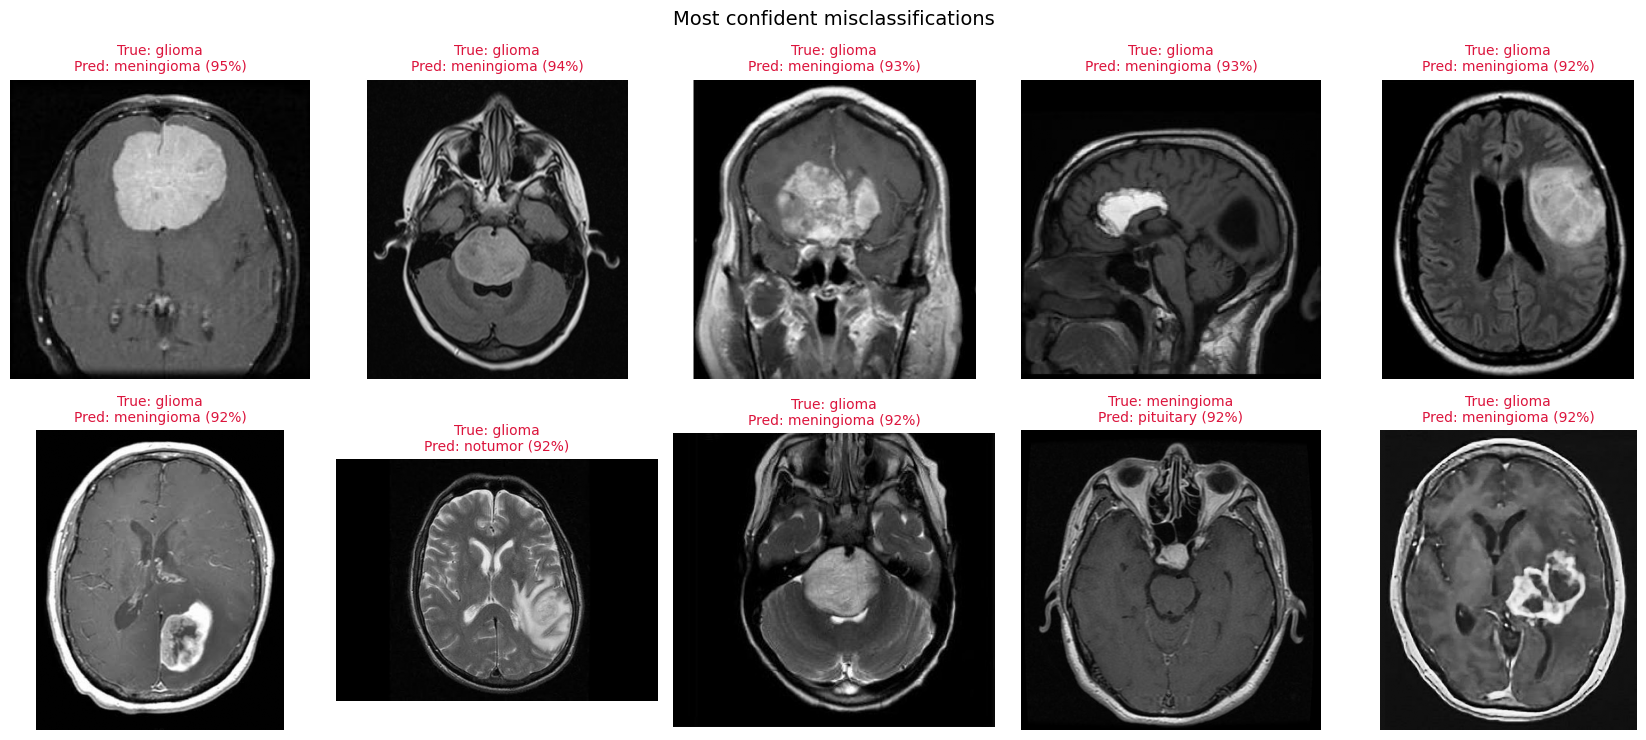


Saved confusion_matrix.png and metrics_2d.json to Google Drive


In [ ]:
# ============================================================
# Cell 6: Test-set evaluation (confusion matrix, per-class metrics)
# ============================================================
import json
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, balanced_accuracy_score)

# ---------- 1) Predict on the test set ----------
model.eval()
all_probs, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device, non_blocking=True)
        with torch.amp.autocast("cuda", enabled=device.type == "cuda"):
            logits = model(x)
        all_probs.append(torch.softmax(logits.float(), dim=1).cpu())
        all_labels.append(y)
probs = torch.cat(all_probs).numpy()
y_true = torch.cat(all_labels).numpy()
y_pred = probs.argmax(1)

acc = accuracy_score(y_true, y_pred)
bal = balanced_accuracy_score(y_true, y_pred)
print(f"Test images            : {len(y_true)}")
print(f"Test accuracy          : {acc:.4f}")
print(f"Balanced accuracy      : {bal:.4f}")
print(f"Misclassified          : {(y_true != y_pred).sum()}\n")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

# ---------- 2) Confusion matrix (counts + row-normalised) ----------
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".1%", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title("Confusion matrix (% of true class)")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/neuroscan-ai/confusion_matrix.png", dpi=150)
plt.show()

# ---------- 3) Most confident mistakes ----------
wrong = np.where(y_true != y_pred)[0]
wrong = wrong[np.argsort(-probs[wrong].max(1))][:10]
if len(wrong):
    fig, axes = plt.subplots(2, 5, figsize=(17, 7.5))
    for ax, i in zip(axes.ravel(), wrong):
        ax.imshow(Image.open(test_df.loc[i, "path"]).convert("L"), cmap="gray")
        ax.set_title(f"True: {IDX_TO_CLASS[y_true[i]]}\nPred: {IDX_TO_CLASS[y_pred[i]]} ({probs[i].max():.0%})",
                     fontsize=10, color="crimson")
        ax.axis("off")
    for ax in axes.ravel()[len(wrong):]:
        ax.axis("off")
    plt.suptitle("Most confident misclassifications", fontsize=14)
    plt.tight_layout(); plt.show()

# ---------- 4) Save metrics for the README ----------
report = classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True)
metrics = {"test_accuracy": acc, "balanced_accuracy": bal, "val_accuracy": best_acc,
           "n_test": int(len(y_true)), "per_class": {c: report[c] for c in CLASSES},
           "confusion_matrix": cm.tolist(), "classes": CLASSES}
with open("/content/drive/MyDrive/neuroscan-ai/metrics_2d.json", "w") as f:
    json.dump(metrics, f, indent=2)
print("\nSaved confusion_matrix.png and metrics_2d.json to Google Drive")

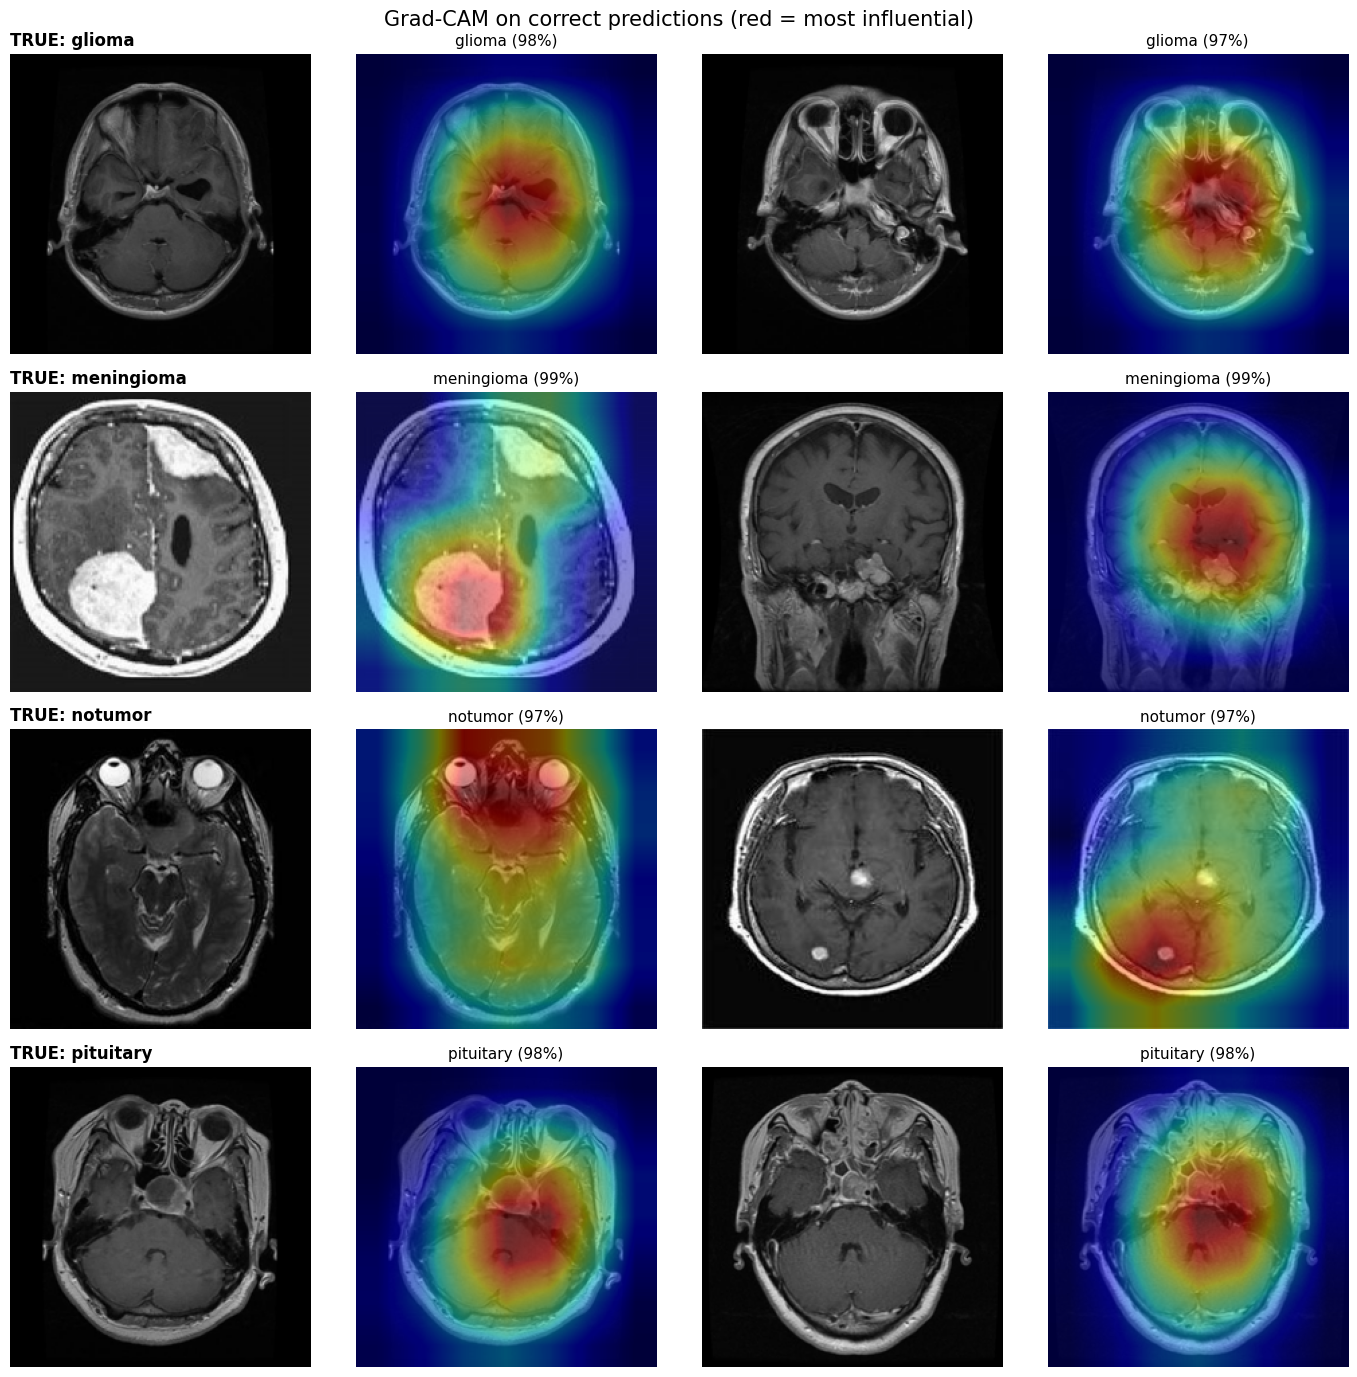

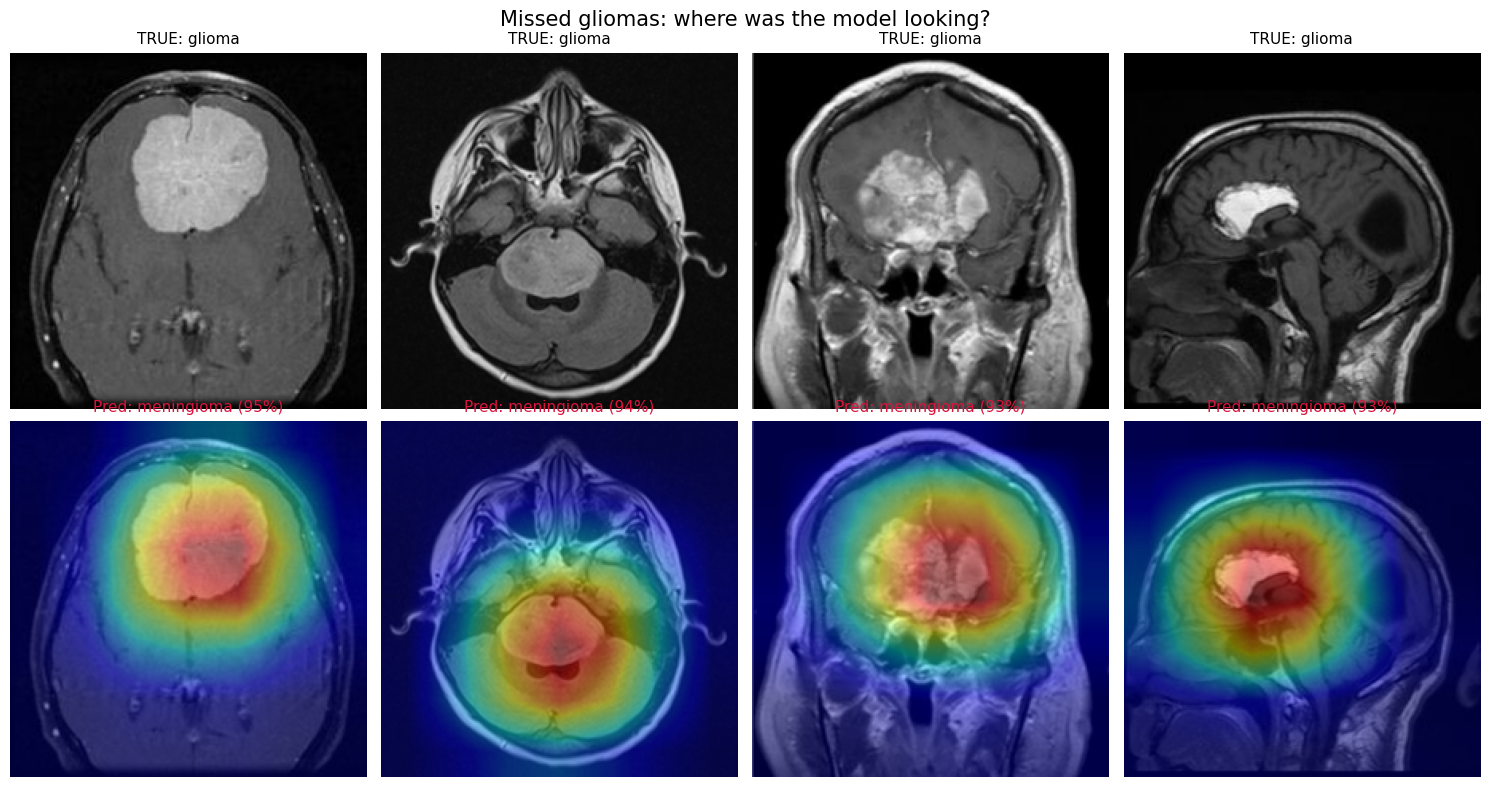

Glioma misses by predicted class: {'notumor': 20, 'meningioma': 42, 'pituitary': 1}


In [ ]:
# ============================================================
# Cell 7: Grad-CAM explainability + reusable prediction function
# ============================================================
import torch.nn.functional as F
import matplotlib.cm as cm_lib

class GradCAM:
    """Grad-CAM on the last conv block of ResNet18 (layer4[-1])."""
    def __init__(self, model, target_layer):
        self.model, self.acts, self.grads = model, None, None
        target_layer.register_forward_hook(self._save)
    def _save(self, module, inp, out):
        self.acts = out.detach()
        out.register_hook(lambda g: setattr(self, "grads", g.detach()))
    def __call__(self, x, class_idx=None):
        self.model.eval()
        self.model.zero_grad()
        logits = self.model(x)
        probs = torch.softmax(logits.detach(), dim=1)[0]
        if class_idx is None:
            class_idx = int(logits.argmax(1))
        logits[0, class_idx].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.cpu().numpy(), class_idx, probs.cpu().numpy()

gradcam = GradCAM(model, model.layer4[-1])

def predict_image(path):
    """Return (predicted class, probabilities, heatmap, display image) for one file."""
    img = Image.open(path).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device)
    cam, idx, probs = gradcam(x)
    return IDX_TO_CLASS[idx], probs, cam, np.array(img.resize((IMG_SIZE, IMG_SIZE)))

def overlay(img, cam, alpha=0.45):
    heat = cm_lib.jet(cam)[..., :3]
    return np.clip((1 - alpha) * (img / 255.0) + alpha * heat, 0, 1)

# ---------- 1) Correct, confident examples: 2 per class ----------
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for r, c in enumerate(CLASSES):
    idxs = [i for i in np.argsort(-probs.max(1)) if y_true[i] == y_pred[i] == CLASS_TO_IDX[c]][:2]
    for k, i in enumerate(idxs):
        pred, p, cam, img = predict_image(test_df.loc[i, "path"])
        axes[r, 2*k].imshow(img); axes[r, 2*k].axis("off")
        axes[r, 2*k+1].imshow(overlay(img, cam)); axes[r, 2*k+1].axis("off")
        axes[r, 2*k+1].set_title(f"{pred} ({p.max():.0%})", fontsize=11)
    axes[r, 0].set_title(f"TRUE: {c}", loc="left", fontsize=12, fontweight="bold")
plt.suptitle("Grad-CAM on correct predictions (red = most influential)", fontsize=15)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/neuroscan-ai/gradcam_correct.png", dpi=150)
plt.show()

# ---------- 2) Glioma cases the model missed ----------
miss = [i for i in range(len(y_true)) if y_true[i] == CLASS_TO_IDX["glioma"] and y_pred[i] != y_true[i]]
miss = sorted(miss, key=lambda i: -probs[i].max())[:4]
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for k, i in enumerate(miss):
    pred, p, cam, img = predict_image(test_df.loc[i, "path"])
    axes[0, k].imshow(img); axes[0, k].axis("off"); axes[0, k].set_title("TRUE: glioma", fontsize=11)
    axes[1, k].imshow(overlay(img, cam)); axes[1, k].axis("off")
    axes[1, k].set_title(f"Pred: {pred} ({p.max():.0%})", color="crimson", fontsize=11)
plt.suptitle("Missed gliomas: where was the model looking?", fontsize=15)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/neuroscan-ai/gradcam_missed_glioma.png", dpi=150)
plt.show()

# Where did the glioma misses go?
print("Glioma misses by predicted class:",
      dict(Counter(IDX_TO_CLASS[y_pred[i]] for i in np.where((y_true == 0) & (y_pred != 0))[0])))

In [ ]:
# ============================================================
# Cell 8: Standalone inference module + demo samples
# ============================================================
import shutil, time

DEPLOY = "/content/drive/MyDrive/neuroscan-ai/deploy"
os.makedirs(f"{DEPLOY}/samples", exist_ok=True)

# ---------- 1) Write predict.py (runs on CPU, no notebook variables needed) ----------
predict_code = r'''
import base64, io
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.cm as cm_lib
from PIL import Image
from torchvision import models, transforms


class NeuroScanClassifier:
    """ResNet18 brain-tumor classifier with Grad-CAM. CPU inference."""

    def __init__(self, ckpt_path, device="cpu"):
        ck = torch.load(ckpt_path, map_location=device, weights_only=True)
        self.device = device
        self.classes = ck["classes"]
        self.size = ck["img_size"]
        self.val_acc = ck.get("val_acc")

        net = models.resnet18(weights=None)
        net.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(net.fc.in_features, len(self.classes)))
        net.load_state_dict(ck["state_dict"])
        self.model = net.eval().to(device)

        self.tf = transforms.Compose([
            transforms.Resize((self.size, self.size)),
            transforms.ToTensor(),
            transforms.Normalize(ck["mean"], ck["std"]),
        ])
        self._acts = None
        self._grads = None
        self.model.layer4[-1].register_forward_hook(self._hook)

    def _hook(self, module, inp, out):
        self._acts = out.detach()
        out.register_hook(lambda g: setattr(self, "_grads", g.detach()))

    def predict(self, image):
        """image: PIL.Image or file path. Returns a JSON-friendly dict."""
        if not isinstance(image, Image.Image):
            image = Image.open(image)
        img = image.convert("RGB")
        x = self.tf(img).unsqueeze(0).to(self.device)

        self.model.zero_grad()
        with torch.enable_grad():
            logits = self.model(x)
            idx = int(logits.argmax(1))
            logits[0, idx].backward()
        probs = torch.softmax(logits.detach(), dim=1)[0].cpu().numpy()

        w = self._grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self._acts).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=(self.size, self.size), mode="bilinear", align_corners=False)[0, 0]
        cam = ((cam - cam.min()) / (cam.max() - cam.min() + 1e-8)).cpu().numpy()

        base = np.array(img.resize((self.size, self.size))) / 255.0
        heat = cm_lib.jet(cam)[..., :3]
        overlay = np.clip(0.55 * base + 0.45 * heat, 0, 1)

        return {
            "label": self.classes[idx],
            "confidence": float(probs[idx]),
            "probabilities": {c: float(p) for c, p in zip(self.classes, probs)},
            "heatmap_png": self._to_b64(overlay),
            "original_png": self._to_b64(base),
        }

    @staticmethod
    def _to_b64(arr):
        buf = io.BytesIO()
        Image.fromarray((arr * 255).astype(np.uint8)).save(buf, format="PNG")
        return base64.b64encode(buf.getvalue()).decode()
'''
with open(f"{DEPLOY}/predict.py", "w") as f:
    f.write(predict_code.strip() + "\n")
shutil.copy(CKPT, f"{DEPLOY}/NeuroScan_AI_resnet18.pth")
print("Wrote predict.py and copied checkpoint to", DEPLOY)

# ---------- 2) Test the module on CPU (exactly as the web app will use it) ----------
import importlib.util
spec = importlib.util.spec_from_file_location("predict_mod", f"{DEPLOY}/predict.py")
mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
clf = mod.NeuroScanClassifier(f"{DEPLOY}/NeuroScan_AI_resnet18.pth", device="cpu")

agree, n_test, times = 0, 40, []
for i in random.Random(1).sample(range(len(test_df)), n_test):
    t0 = time.time()
    out = clf.predict(test_df.loc[i, "path"])
    times.append(time.time() - t0)
    agree += out["label"] == IDX_TO_CLASS[y_pred[i]]
print(f"\nCPU module agrees with the GPU model on {agree}/{n_test} test images")
print(f"CPU latency per image: {np.mean(times)*1000:.0f} ms (includes Grad-CAM)")
print("Example output keys:", list(out.keys()))

# ---------- 3) Pick demo samples (confident, correctly classified, from the test set) ----------
chosen = {}
order = np.argsort(-probs.max(1))
for c in CLASSES:
    ok = [i for i in order if y_true[i] == y_pred[i] == CLASS_TO_IDX[c]]
    chosen[c] = ok[:2] if c == "glioma" else ok[:1]
for c, idxs in chosen.items():
    for k, i in enumerate(idxs, 1):
        src = test_df.loc[i, "path"]
        ext = os.path.splitext(src)[1].lower()
        name = f"{c}{'' if len(idxs) == 1 else k}{ext}"
        shutil.copy(src, f"{DEPLOY}/samples/{name}")
print("\nDemo samples:", sorted(os.listdir(f"{DEPLOY}/samples")))

print("\nDeploy folder contents:")
for f in sorted(os.listdir(DEPLOY)):
    p = os.path.join(DEPLOY, f)
    if os.path.isfile(p):
        print(f"  {f}  ({os.path.getsize(p)/1e6:.1f} MB)")

Wrote predict.py and copied checkpoint to /content/drive/MyDrive/neuroscan-ai/deploy

CPU module agrees with the GPU model on 40/40 test images
CPU latency per image: 283 ms (includes Grad-CAM)
Example output keys: ['label', 'confidence', 'probabilities', 'heatmap_png', 'original_png']

Demo samples: ['glioma1.jpg', 'glioma2.jpg', 'meningioma.jpg', 'notumor.jpg', 'pituitary.jpg']

Deploy folder contents:
  NeuroScan_AI_resnet18.pth  (44.8 MB)
  predict.py  (0.0 MB)
